# Writeup HZZ for begginers

By Martin Aldana

This is my writeup for the ATLAS Open Data notebook for the measurements of the decay of the Higgs Boson into 2Z and then 4l. The original notebook separates everything into three activities, each using a different dataset. Through this notebook I'll use the same dataset, which corresponds to the one used in acttivity 3 of the original notebook. I made this desicion because activity 3 includes elements from the two previous ones and is also the most complete one in terms of content.

During this writeup I'll go through the step by step basis on how to obtain the plot for the Higgs Peak; including my solutions to the bonus activities that are presented in the original notebook. I'll also be mentioning my mistakes and difficulties while following the original notebook, hopefully this will be of use to the reader. I'll take for granted that the reader has alredy read the theoretical basis explained in the original notebook.

## Setup for the notebook

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import uproot
import matplotlib.text
import sys
#Importing standard libraries

In [2]:
from atlasopenmagic import install_from_environment
import atlasopenmagic as atom   
#Installing the ATLAS Open Data Magic Library and importing it as atom. This library is used to access ATLAS Open Data and perform various analyses on it.

Choosing the 13 TeV center of mass energy dataset for this notebook. This corresponds to Run 2 spanning across 2015 to 2018

In [96]:
atom.set_release('2025e-13tev-beta')

Release '2025e-13tev-beta' already active with cached metadata.
Active release: 2025e-13tev-beta. (Datasets path: REMOTE)


Setting up the skim to 4lep; this filters in all the events that had 4 leptons. WHich is what we want since we are measuring its decay branch of ZZ*. It is worth noting that across all the posible decays this particle has, decaying into a pair of Z boson has a branching ratio of ~2.62% https://pdg.lbl.gov/2025/reviews/rpp2025-rev-higgs-boson.pdf 

Also the original notebook doesn't mention this, but the reason the Higgs peak is measured is to get its mass and the reason we want to use this relatively weird decay branch is beacause it is cleaner than other decay branches (in the sense that it does not have as much background noise and does not have any neutrinos that are prone to being undetected)

In [4]:
skim='4lep'

In [97]:
files_list = atom.get_urls('data', skim, protocol = 'https', cache = True) #gathering the urls that fit our criteria

In [6]:
files_list

['simplecache::https://opendata.cern.ch/eos/opendata/atlas/rucio/opendata/ODEO_FEB2025_v0_4lep_mc_345060.PowhegPythia8EvtGen_NNLOPS_nnlo_30_ggH125_ZZ4l.4lep.root']

MISSING EXPLANATION

In [98]:
leps = []

for file in files_list:
    print(f'Analyzing file: {file} ({files_list.index(file)+1}/{len(files_list)})')

    # open files and turn into a structured array
    analysis = uproot.open(file +':analysis')
    attributes = ['pt','eta','phi','e','charge','flavor','tight']
    aliases_dict = {'pt':'lep_pt','eta':'lep_eta','phi':'lep_phi','e':'lep_e',
                           'charge':'lep_charge','flavor':'lep_type','tight':'lep_isTightID'}
    leps_partial = analysis.arrays(attributes, aliases = aliases_dict)

    # append the current structured array to all previous structured arrays
    leps = np.concatenate([leps,leps_partial], axis=0)
print('Completed processing all files')

Analyzing file: simplecache::https://opendata.cern.ch/eos/opendata/atlas/rucio/opendata/ODEO_FEB2025_v0_4lep_data15_periodD.4lep.root (1/16)
Analyzing file: simplecache::https://opendata.cern.ch/eos/opendata/atlas/rucio/opendata/ODEO_FEB2025_v0_4lep_data15_periodE.4lep.root (2/16)
Analyzing file: simplecache::https://opendata.cern.ch/eos/opendata/atlas/rucio/opendata/ODEO_FEB2025_v0_4lep_data15_periodF.4lep.root (3/16)
Analyzing file: simplecache::https://opendata.cern.ch/eos/opendata/atlas/rucio/opendata/ODEO_FEB2025_v0_4lep_data15_periodG.4lep.root (4/16)
Analyzing file: simplecache::https://opendata.cern.ch/eos/opendata/atlas/rucio/opendata/ODEO_FEB2025_v0_4lep_data15_periodH.4lep.root (5/16)
Analyzing file: simplecache::https://opendata.cern.ch/eos/opendata/atlas/rucio/opendata/ODEO_FEB2025_v0_4lep_data15_periodJ.4lep.root (6/16)
Analyzing file: simplecache::https://opendata.cern.ch/eos/opendata/atlas/rucio/opendata/ODEO_FEB2025_v0_4lep_data16_periodA.4lep.root (7/16)
Analyzing fil

In [ ]:
s

In [ ]:
leps.fields

AttributeError: no field named 'columns'

In [8]:
attributes = ['pt', 'eta', 'phi', 'e', 'charge', 'flavour', 'isTightID']
#esto de arriba hace los aliases de mis variables
aliases_dict = {'pt': 'lep_pt', 'eta': 'lep_eta', 'phi': 'lep_phi', 'e': 'lep_e', 'charge': 'lep_charge', 'flavour': 'lep_type', 'isTightID': 'lep_isTightID'}
#esto de aqui arriba mapea mis aliases a sus variables correspondientes en el archivo root

In [9]:
leps = analysis.arrays(attributes, aliases=aliases_dict)

In [54]:
sorter = np.argsort(leps.pt, axis=1)[:,::-1][:,:4]
#aaa ya esto causaba error pq toca asegurarse de que solo estan los 4 leptones con mayor pt, y no todos los demas

In [99]:
leps = leps[np.argsort(leps.pt, axis=1)[:,::-1]][:,:4]
#Metodo mas compacto por parte de ccern open data

In [56]:
leps = leps[sorter]

In [58]:
px = leps.pt * np.sin(leps.phi)
py = leps.pt * np.cos(leps.phi)
pz = leps.pt * np.sinh(leps.eta)

In [62]:
vecs = np.array([leps.e, px, py, pz, leps.charge, leps.flavor, leps.tight])

In [14]:
vecs.shape

(7, 424880, 4)

In [109]:
Z_0 = vecs[:,:,0] + vecs[:,:,1]
Z_1 = vecs[:,:,0] + vecs[:,:,2]
Z_2 = vecs[:,:,0] + vecs[:,:,3]
Z_3 = vecs[:,:,1] + vecs[:,:,2]
Z_4 = vecs[:,:,1] + vecs[:,:,3]
Z_5 = vecs[:,:,2] + vecs[:,:,3]

In [149]:
Z_bossons = np.array([Z_0, Z_1, Z_2, Z_5, Z_4, Z_3])
Z_bossons.shape

(6, 7, 1515848)

In [150]:
charge_cut = Z_bossons[:, 4] == 0
flavour_cut = (Z_bossons[:,5] == 22) | (Z_bossons[:, 5] == 26)
tight_cut = Z_bossons[:, 6] == 2

In [135]:
cut = charge_cut & flavour_cut & tight_cut

In [113]:
Z_masses = np.sqrt(np.abs(Z_bossons[:, 0, :]**2 - Z_bossons[:, 1, :]**2 - Z_bossons[:, 2, :]**2 - Z_bossons[:, 3, :]**2))
Z_cut_masses = np.copy(Z_masses)
Z_cut_masses[~cut] = 0
Z_mass = np.ndarray.flatten(Z_cut_masses)
Z_mass = Z_mass[Z_mass !=0]

In [68]:
x_min, x_max = 10, 160
bin_width = 1
bin_edges = np.arange(start=x_min, stop=x_max+1, step=bin_width)
bin_centers = bin_edges[:-1] + bin_width/2

In [69]:
counts, _ = np.histogram(Z_mass, bins=bin_edges)

In [87]:
count_error = np.sqrt(counts)

<>:11: SyntaxWarning: invalid escape sequence '\m'
<>:11: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_830/1792574762.py:11: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel('Di-lepton invarient mass [${m_{\mu\mu} \ or \ m_{ee}}$]', x=1, horizontalalignment = 'right')


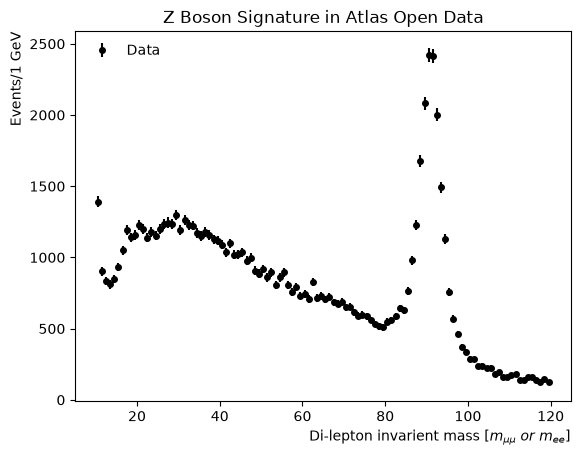

In [114]:
x_min, x_max = 10,120 #Unidades gente, aqui estan en GeV (las masas)
bin_width = 1
bin_edges = np.arange(start = x_min, stop = x_max+1, step = bin_width)
bin_centers = bin_edges[:-1] + bin_width/2
counts, _ = np.histogram(Z_mass, bins=bin_edges)
count_errors = np.sqrt(counts)

#plot
plt.errorbar(x = bin_centers, y = counts, yerr = count_errors, fmt = 'ko', label = 'Data', markersize = 4)
plt.title('Z Boson Signature in Atlas Open Data')
plt.xlabel('Di-lepton invarient mass [${m_{\mu\mu} \ or \ m_{ee}}$]', x=1, horizontalalignment = 'right')
plt.ylabel('Events/' + str(bin_width) + ' GeV', y=1, horizontalalignment = 'right')
plt.legend(frameon = False, loc = 'upper left')
plt.show()

In [ ]:
#Bueno mi distribucion no fue del todo buena tampoco se pq tengo tanto error y auun menos pq tengo tanto error, asuumo que es pq se me descargo rapido el archivo depronto me faltan datos

Entender de aqui abajo pq esta parte no me quedo clara. Pero creo que termino esto y ya puedo saltar a otro notebook

In [151]:
H_0 = Z_bossons[0,:,:] + Z_bossons[5,:,:]
H_1 = Z_bossons[1,:,:] + Z_bossons[4,:,:]
H_2 = Z_bossons[2,:,:] + Z_bossons[3,:,:] 
# puedes hacer esta o te facilitas la vida con
Higgs= Z_bossons[:3] + Z_bossons[3:]
# split the array into two halfs
Z_mass_upper = Z_masses[:3]
Z_mass_lower = Z_masses[3:]

# define our mass constraints
Z_on_min, Z_on_max = 50, 106
Z_off_min, Z_off_max = 17.5, 115

# return true for all indices where a on\off shell pair exists
Z_up_is_on = (Z_mass_upper > Z_on_min) & (Z_mass_upper < Z_on_max)
Z_up_is_off = (Z_mass_upper > Z_off_min) & (Z_mass_upper < Z_off_max)
Z_low_is_on = (Z_mass_lower > Z_on_min) & (Z_mass_lower < Z_on_max)
Z_low_is_off = (Z_mass_lower > Z_off_min) & (Z_mass_lower < Z_off_max)

shell_cut = (Z_up_is_on & Z_low_is_off) | (Z_up_is_off & Z_low_is_on)

In [152]:
shell_cut.shape

(3, 1515848)

In [153]:
H_charge_cut = charge_cut[:3] & charge_cut[3:]
H_flavor_cut = flavour_cut[:3] & flavour_cut[3:]
H_tight_cut = tight_cut[:3] & tight_cut[3:]

In [154]:
H_tight_cut.shape

(3, 1515848)

In [161]:
H_mass = np.sqrt(np.abs(Higgs[:,0]**2-Higgs[:,1]**2-Higgs[:,2]**2-Higgs[:,3]**2))[1]

In [163]:
# choose cuts
cut = shell_cut & H_charge_cut & H_flavor_cut & H_tight_cut
cut = cut[0] | cut[1] | cut[2]
# apply cuts


In [164]:
H_mass = H_mass[cut]

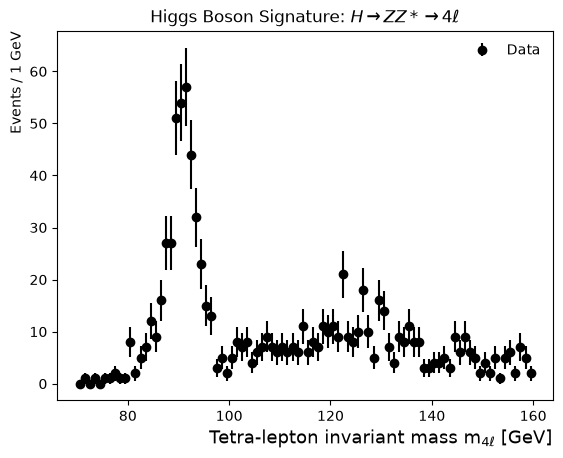

In [165]:
# x-axis range of the plot
xmin = 70 #GeV
xmax = 160 #GeV

# Histogram bin setup
bin_width = 1 #GeV
bin_edges = np.arange(start = xmin, stop = xmax + bin_width, step = bin_width)
bin_centers = bin_edges[:-1] + bin_width/2

# Creating histogram from data
counts, _ = np.histogram(H_mass, bins = bin_edges)
count_errors = np.sqrt(counts) # poisson approximation of the error

# Plot
axs = plt.gca()
axs.errorbar(x = bin_centers, y = counts, yerr = count_errors,
                    fmt = 'ko', # 'k' means black and 'o' is for circles
                    label = 'Data')
axs.set_xlabel(r'Tetra-lepton invariant mass $\mathrm{m_{4\ell}}$ [GeV]', 
                     fontsize = 13, x = 1, horizontalalignment = 'right' )
axs.set_ylabel('Events / ' + str(bin_width) + ' GeV', y = 1, horizontalalignment = 'right')
plt.title('Higgs Boson Signature: ' + r'$H \rightarrow ZZ* \rightarrow 4\ell$')
axs.legend(frameon = False)
plt.show()